# Prevedere il prezzo in euro di un dataset di immobili

In [138]:
from copy import copy

import pandas as pd
import matplotlib.pyplot as plt
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler, OneHotEncoder


## importare il df

In [104]:
path=('dataset_case_regressione.csv')
df = pd.read_csv(path)
df.head(300)

,id_annuncio,superficie_mq,stanze,distanza_centro_km,eta_immobile_anni,zona,ascensore,prezzo_euro
0,ANN-0001,45.0,2,8.0,5.0,Semicentro,Si,247044
1,ANN-0002,124.0,4,11.5,53.0,Semicentro,Si,484877
2,ANN-0003,110.0,3,6.8,25.0,Semicentro,No,367667
3,ANN-0004,85.0,2,9.5,32.0,NaN,Si,396385
4,ANN-0005,85.0,2,13.4,10.0,Periferia,Si,346220
...,...,...,...,...,...,...,...,...
295,ANN-0296,95.0,4,7.7,NaN,Semicentro,Si,404431
296,ANN-0297,133.0,5,6.1,11.0,Semicentro,No,515463
297,ANN-0298,85.0,3,1.9,58.0,Semicentro,Si,323802
298,ANN-0299,68.0,2,1.0,NaN,NaN,No,341309


In [105]:
print('Struttura df righe', df.shape[0])
print('Struttura df colonne', df.shape[1])

print(df.dtypes)


Struttura df righe 320
Struttura df colonne 8
id_annuncio               str
superficie_mq         float64
stanze                  int64
distanza_centro_km    float64
eta_immobile_anni     float64
zona                      str
ascensore                 str
prezzo_euro             int64
dtype: object


In [106]:
print('righe_duplicate', df.duplicated().sum()) #somma delle righe duplicate
# Exploratory data analysis

righe_duplicate 0


In [107]:
#valori nulli
print('righe_nulle', df.isnull().sum()) #somma delle righe duplicate

df.index

righe_nulle id_annuncio            0
superficie_mq         22
stanze                 0
distanza_centro_km     0
eta_immobile_anni     30
zona                  13
ascensore             10
prezzo_euro            0
dtype: int64


RangeIndex(start=0, stop=320, step=1)

In [108]:
mask = df.isna()
df[mask]

,id_annuncio,superficie_mq,stanze,distanza_centro_km,eta_immobile_anni,zona,ascensore,prezzo_euro
0,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...
315,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
316,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
317,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
318,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


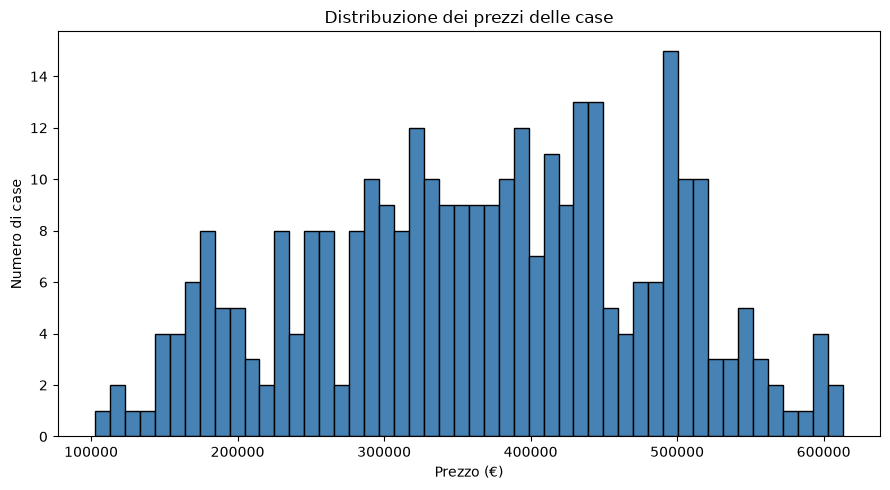

In [109]:
# fammi grafico a barre della distribuzione dei prezzi delle case del dataset, i nomi delle colonne del dataset sono: superifice_mq, stanze, distanza_centro_km, eta_immbile_anni, zona, ascensore, prezzo_euro
# scatterplot prezzo per superficie

prezzi = df["prezzo_euro"].dropna()

plt.figure(figsize=(9, 5))
plt.hist(prezzi, bins=50, color="steelblue", edgecolor="black")
plt.title("Distribuzione dei prezzi delle case")
plt.xlabel("Prezzo (€)")
plt.ylabel("Numero di case")
plt.tight_layout()
plt.show()

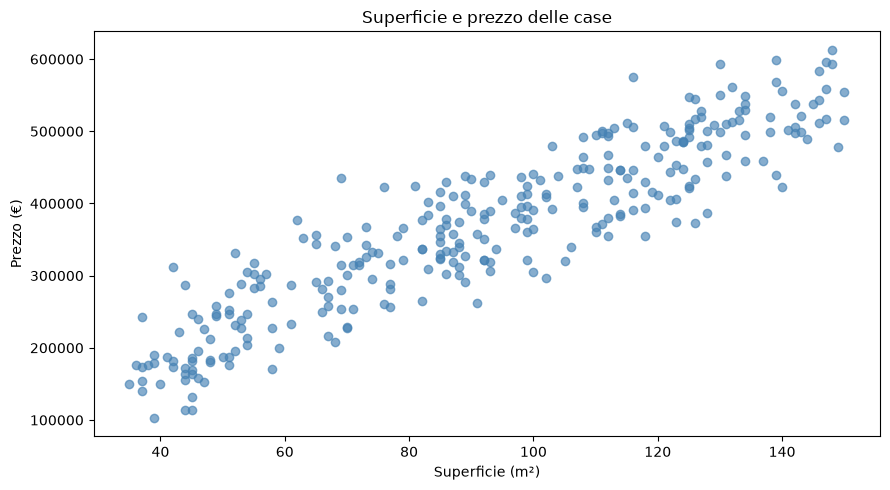

In [110]:
dati = df[["superficie_mq", "prezzo_euro"]].dropna()

plt.figure(figsize=(9, 5))
plt.scatter(dati["superficie_mq"], dati["prezzo_euro"],
            color="steelblue", alpha=0.65)
plt.title("Superficie e prezzo delle case")
plt.xlabel("Superficie (m²)")
plt.ylabel("Prezzo (€)")
plt.tight_layout()
plt.show()

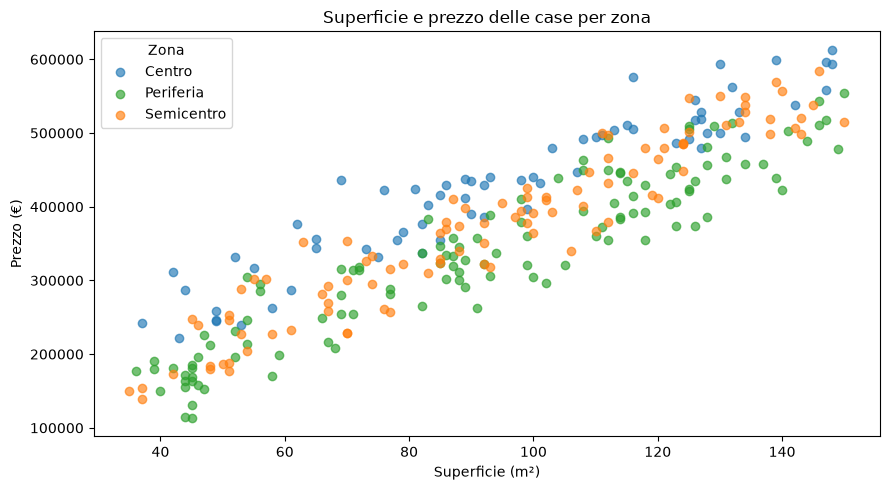

In [111]:
import pandas as pd
import matplotlib.pyplot as plt

dati = df[["superficie_mq", "prezzo_euro"]].copy()

if "zona" in df.columns:
    dati["zona"] = df["zona"]
else:
    dati["zona"] = pd.cut(
        df["distanza_centro_km"],
        bins=[0, 2, 5, float("inf")],
        labels=["Centro", "Semicentro", "Periferia"],
        include_lowest=True,
    )

dati = dati.dropna()

colori = {
    "Centro": "tab:blue",
    "Semicentro": "tab:orange",
    "Periferia": "tab:green",
}

plt.figure(figsize=(9, 5))

for zona, gruppo in dati.groupby("zona", observed=True):
    plt.scatter(
        gruppo["superficie_mq"],
        gruppo["prezzo_euro"],
        color=colori[zona],
        label=zona,
        alpha=0.65,
    )

plt.title("Superficie e prezzo delle case per zona")
plt.xlabel("Superficie (m²)")
plt.ylabel("Prezzo (€)")
plt.legend(title="Zona")
plt.tight_layout()
plt.show()

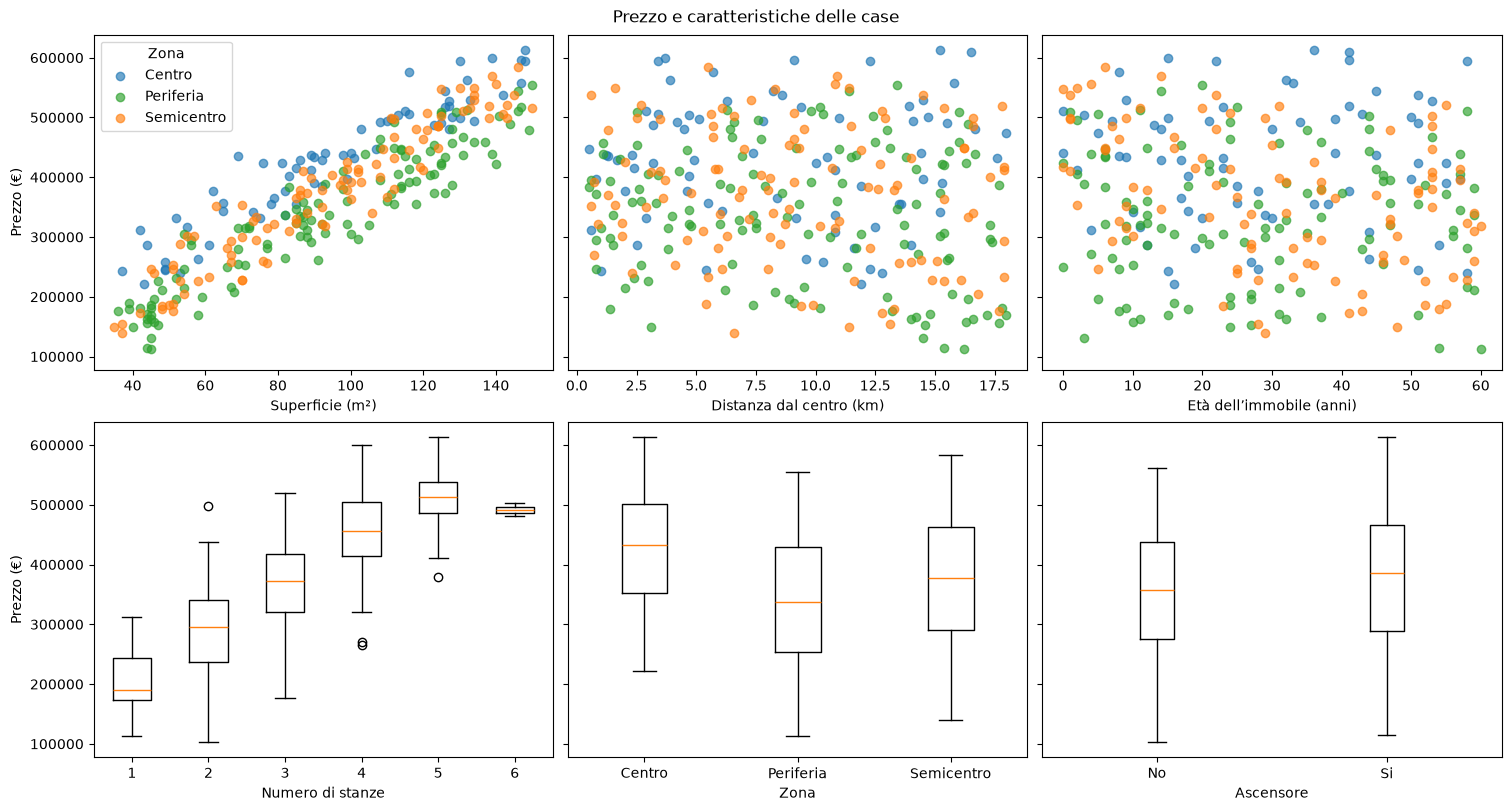

In [112]:


variabili_scatter = [
    ("superficie_mq", "Superficie (m²)"),
    ("distanza_centro_km", "Distanza dal centro (km)"),
    ("eta_immobile_anni", "Età dell’immobile (anni)"),
]

variabili_box = [
    ("stanze", "Numero di stanze"),
    ("zona", "Zona"),
    ("ascensore", "Ascensore"),
]

colori_zona = {
    "Centro": "tab:blue",
    "Semicentro": "tab:orange",
    "Periferia": "tab:green",
}

fig, assi = plt.subplots(
    2, 3, figsize=(15, 8), sharey=True, constrained_layout=True
)

# Prima riga con gli scatterplot colorati per zona
gruppi_zona = df.groupby("zona", observed=True)

for ax, (colonna, etichetta) in zip(assi[0], variabili_scatter):
    for zona, gruppo in gruppi_zona:
        dati = gruppo[[colonna, "prezzo_euro"]].dropna()
        ax.scatter(
            dati[colonna],
            dati["prezzo_euro"],
            color=colori_zona.get(zona, "gray"),
            label=str(zona),
            alpha=0.65,
        )
    ax.set_xlabel(etichetta)

assi[0, 0].legend(title="Zona")

# Seconda riga con i box plot dei prezzi per gruppo
for ax, (colonna, etichetta) in zip(assi[1], variabili_box):
    dati = df[[colonna, "prezzo_euro"]].dropna()
    gruppi = list(dati.groupby(colonna, observed=True)["prezzo_euro"])

    ax.boxplot([prezzi.to_numpy() for _, prezzi in gruppi])
    ax.set_xticks(range(1, len(gruppi) + 1))
    ax.set_xticklabels([str(valore) for valore, _ in gruppi])
    ax.set_xlabel(etichetta)

assi[0, 0].set_ylabel("Prezzo (€)")
assi[1, 0].set_ylabel("Prezzo (€)")
assi[0, 0].ticklabel_format(axis="y", style="plain")

fig.suptitle("Prezzo e caratteristiche delle case")
plt.show()

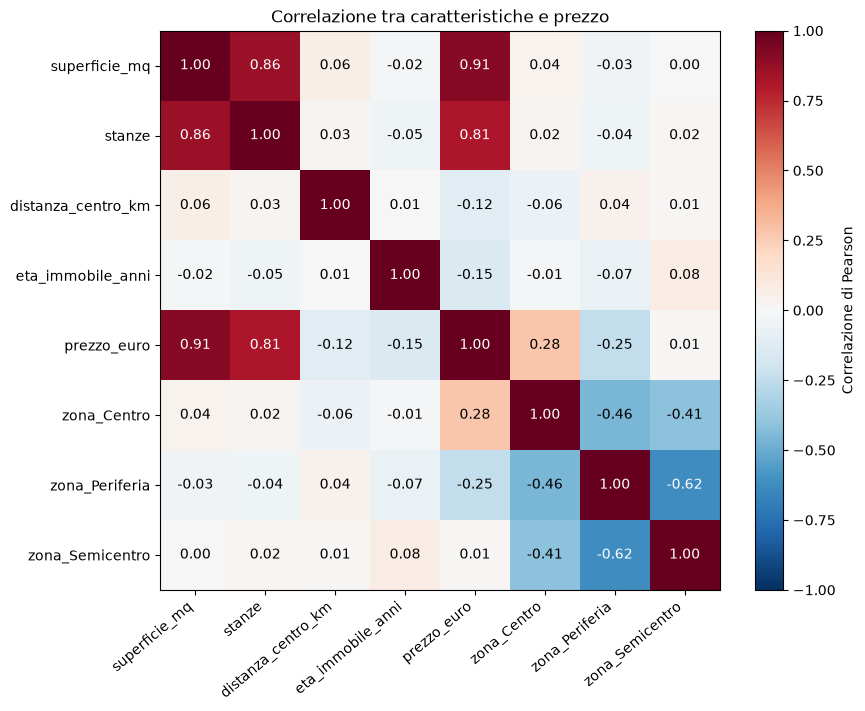

In [113]:
import matplotlib.pyplot as plt

colonne = [
    "superficie_mq",
    "stanze",
    "distanza_centro_km",
    "eta_immobile_anni",
    "ascensore",
    "prezzo_euro",
]

indicatori_zona = pd.get_dummies(df["zona"], prefix="zona", dtype=int)

# Propaga le zone mancanti agli indicatori
indicatori_zona = indicatori_zona.where(df["zona"].notna(), axis=0)

dati = pd.concat([df[colonne], indicatori_zona], axis=1)
matrice = dati.corr(method="pearson", numeric_only=True)

fig, ax = plt.subplots(figsize=(9, 7), constrained_layout=True)
mappa = ax.imshow(matrice.to_numpy(), cmap="RdBu_r", vmin=-1, vmax=1)

posizioni = range(len(matrice))
ax.set_xticks(posizioni)
ax.set_yticks(posizioni)
ax.set_xticklabels(matrice.columns, rotation=40, ha="right")
ax.set_yticklabels(matrice.index)

for riga in posizioni:
    for colonna in posizioni:
        valore = matrice.iloc[riga, colonna]
        colore = "white" if abs(valore) > 0.6 else "black"
        ax.text(
            colonna, riga, f"{valore:.2f}",
            ha="center", va="center", color=colore,
        )

fig.colorbar(mappa, ax=ax, label="Correlazione di Pearson")
ax.set_title("Correlazione tra caratteristiche e prezzo")
plt.show()

## divisione della tabella tra dati e target (tra x e y)

In [114]:
df.columns

Index(['id_annuncio', 'superficie_mq', 'stanze', 'distanza_centro_km',
       'eta_immobile_anni', 'zona', 'ascensore', 'prezzo_euro'],
      dtype='str')

In [115]:
#elenco colonne numeriche che ci servono
colonne_numeriche = ['superficie_mq', 'stanze', 'distanza_centro_km',
       'eta_immobile_anni']
colonne_categoriche = ['zona','ascensore']
colonne_input = colonne_numeriche + colonne_categoriche
X = df[colonne_input]
y= df['prezzo_euro']

print('dimenisioni x', X.shape)
print('dimenisioni y', y.shape)

dimenisioni x (320, 6)
dimenisioni y (320,)


# suddividiamo tra training e test
si utilizza una funzione che si chiama train_test_split generalemnte si usa il 20% per il test e l'80% per il training, random_state = 42 si usa per rendere riproducibili gli esperimenti
di default il dataset va splittato in 80-20: 80 TRAIN, 20 TEST

In [116]:
from sklearn.model_selection import train_test_split

In [117]:
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f'dimensioni X_train {X_train.shape}')
print(f'dimensioni X_test {X_test.shape}')
print(f'dimensioni y_train {y_train.shape}')
print(f'dimensioni y_test {y_test.shape}')

dimensioni X_train (256, 6)
dimensioni X_test (64, 6)
dimensioni y_train (256,)
dimensioni y_test (64,)


## ci creiamo un modello di regressione con una sola feature per  avere una baseline da confrontare con il nostro modello finale cosi sappiamo che se il nostro modello finale ha una performance peggiore della baseline c'è un problema

In [118]:
modello_semplice = Pipeline(steps=[('imputer', SimpleImputer(strategy="mean")),('regressione',LinearRegression())])
#fit ti allena il modello sui dati di train
#predict predizione dei dati di test
modello_semplice.fit(X_train[['superficie_mq']], y_train)
previsioni_semplice = modello_semplice.predict(X_test[['superficie_mq']])
mean_absolute_error_semplice = mean_absolute_error(y_test, previsioni_semplice)
print(f'errore assoluto medio {mean_absolute_error_semplice:.2f}')
print(type(mean_absolute_error_semplice))

errore assoluto medio 44630.15
<class 'float'>


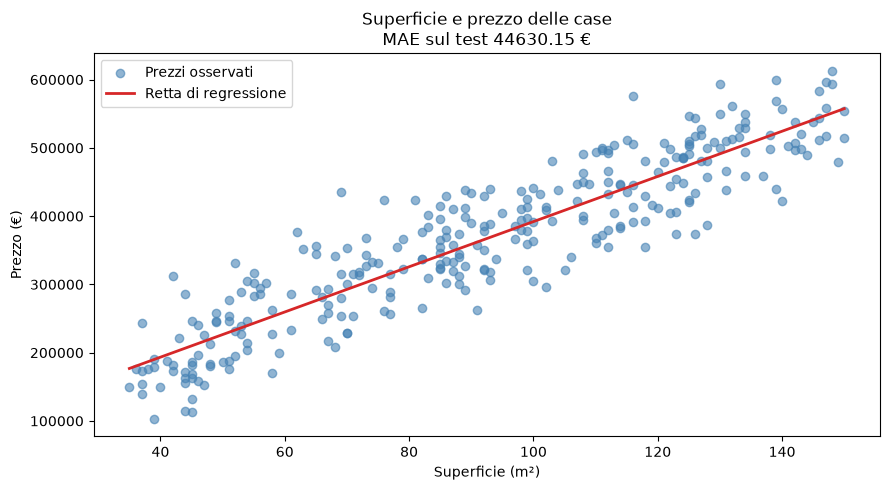

In [119]:


dati = df[["superficie_mq", "prezzo_euro"]].dropna()

# Per disegnare una retta bastano le previsioni ai due estremi
estremi = pd.DataFrame({
    "superficie_mq": [
        dati["superficie_mq"].min(),
        dati["superficie_mq"].max(),
    ]
})
prezzi_retta = modello_semplice.predict(estremi)
mae_test = float(mean_absolute_error_semplice)

plt.figure(figsize=(9, 5))
plt.scatter(
    dati["superficie_mq"],
    dati["prezzo_euro"],
    color="steelblue",
    alpha=0.6,
    label="Prezzi osservati",
)
plt.plot(
    estremi["superficie_mq"],
    prezzi_retta,
    color="tab:red",
    linewidth=2,
    label="Retta di regressione",
)

plt.xlabel("Superficie (m²)")
plt.ylabel("Prezzo (€)")
plt.title(f"Superficie e prezzo delle case\nMAE sul test {mae_test:.2f} €")
plt.legend()
plt.tight_layout()
plt.show()

## Gestire i valori mancati sia per le colonne numeriche che per le colonne categoriche

In [130]:
preparazione_numeri = Pipeline(steps=[('imputer', SimpleImputer(strategy='mean')),('scaler', StandardScaler())])
preparazione_variabili_categoriche= Pipeline(steps=[('imputer', SimpleImputer(strategy='most_frequent')),('encoder', OneHotEncoder(handle_unknown='ignore'))])

preprocessing = ColumnTransformer(
    transformers=[('numeriche', preparazione_numeri,colonne_numeriche), ('categoriche', preparazione_variabili_categoriche,colonne_categoriche)])
prova = copy(preprocessing)
print(prova)
df_preprocessed = prova.fit_transform(X_train)
df_preparato = pd.DataFrame(df_preprocessed)
df_preparato


ColumnTransformer(transformers=[('numeriche',
                                 Pipeline(steps=[('imputer', SimpleImputer()),
                                                 ('scaler', StandardScaler())]),
                                 ['superficie_mq', 'stanze',
                                  'distanza_centro_km', 'eta_immobile_anni']),
                                ('categoriche',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('encoder',
                                                  OneHotEncoder(handle_unknown='ignore'))]),
                                 ['zona', 'ascensore'])])


,0,1,2,3,4,5,6,7,8
0,-1.505788,-1.630297,0.209879,-2.107237e-16,0.0,1.0,0.0,1.0,0.0
1,0.000000,0.849046,0.305313,-5.417125e-01,0.0,0.0,1.0,0.0,1.0
2,-0.005299,0.022598,-0.591762,-1.312787e+00,0.0,1.0,0.0,0.0,1.0
3,-1.410012,-1.630297,0.057186,-3.044587e-01,0.0,0.0,1.0,0.0,1.0
4,-1.761190,-1.630297,-0.114595,1.297004e+00,0.0,1.0,0.0,0.0,1.0
...,...,...,...,...,...,...,...,...,...
251,0.000000,-1.630297,0.477093,-5.417125e-01,1.0,0.0,0.0,0.0,1.0
252,-1.154609,-1.630297,-1.450664,-9.569065e-01,0.0,1.0,0.0,0.0,1.0
253,1.048236,0.849046,1.374168,-1.668668e+00,0.0,1.0,0.0,1.0,0.0
254,-0.739581,0.022598,-1.011670,8.818101e-01,0.0,1.0,0.0,0.0,1.0


In [132]:
modello_completo = Pipeline(steps=[('preprocessing', copy(preprocessing)),('regressore', LinearRegression())]) #faccio pipeline in cui metto nell'ordine il preprocessing e il modello
modello_completo.fit(X_train, y_train) #alleno il modello sui dati di training
y_predict = modello_completo.predict(X_test) #gli faccio fare le predizioni sui dati di test
# r^2 --> quanta variabilità dei nostri dati è spiegata


## Errori

In [140]:
MAE = mean_absolute_error(y_test, y_predict)
MSE = mean_squared_error(y_test, y_predict)
r2 = r2_score(y_test, y_predict)